# Práctica: Evaluación y comparativa de algoritmos de clustering

Se comparan KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering y GaussianMixture sobre seis datasets sintéticos con métricas internas (Silhouette, Davies-Bouldin, Calinski-Harabasz) y externas (ARI y Jaccard).

## 1. Carga de datos y librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, jaccard_score)

archivos = ["aggregation", "D31", "elly-2d10c13s", "rings", "s-set2", "spherical_5_2"]

def cargar(nombre):
    """Lee un .arff y devuelve las coordenadas (x, y) y las etiquetas reales."""
    datos, _ = arff.loadarff(f"{nombre}.arff")
    df = pd.DataFrame(datos)
    y = df.iloc[:, -1].apply(lambda v: v.decode() if isinstance(v, bytes) else v).astype(int).values
    X = df.iloc[:, :2].values.astype(float)
    return X, y

datasets = {n: cargar(n) for n in archivos}
for n, (X, y) in datasets.items():
    print(f"{n:15s} puntos={len(X):5d}  clases reales={len(np.unique(y))}")

aggregation     puntos=  788  clases reales=7
D31             puntos= 3100  clases reales=31
elly-2d10c13s   puntos= 2796  clases reales=10
rings           puntos= 1000  clases reales=3
s-set2          puntos= 5000  clases reales=15
spherical_5_2   puntos=  250  clases reales=5


## 2. Preprocesamiento

Cada dataset se normaliza con `StandardScaler` (media 0, desviación 1). Esto es necesario porque, por ejemplo, `s-set2` tiene coordenadas del orden de cientos de miles y `rings` del orden de decenas, y los algoritmos basados en distancia se verían afectados por la escala.

In [2]:
datos_norm = {n: StandardScaler().fit_transform(X) for n, (X, y) in datasets.items()}

## 3. Configuración de los algoritmos

Para KMeans, Agglomerative (enlace Ward), Spectral (afinidad por vecinos más cercanos) y GaussianMixture se usa `k` igual al número de clases reales de cada dataset. DBSCAN no recibe `k`; su `eps` se estima con el método del codo de la gráfica de distancias al 4.º vecino más cercano (`min_samples=5`), sin usar las etiquetas reales.

In [3]:
def estimar_eps(Xn, min_samples=5):
    """Estima eps con el punto de máxima curvatura de la curva de k-distancias ordenada."""
    d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xn).kneighbors(Xn)
    kd = np.sort(d[:, -1])
    x = np.linspace(0, 1, len(kd))
    yk = (kd - kd.min()) / (kd.max() - kd.min())
    # distancia de cada punto a la recta que une el primero y el último (método del codo)
    idx = np.argmax(np.abs(yk - x))
    return kd[idx]

def modelos(k, eps):
    return {
        "KMeans": KMeans(n_clusters=k, n_init=10, random_state=42),
        "Agglomerative": AgglomerativeClustering(n_clusters=k, linkage="ward"),
        "DBSCAN": DBSCAN(eps=eps, min_samples=5),
        "Spectral": SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                                       n_neighbors=10, random_state=42, assign_labels="kmeans"),
        "GaussianMixture": GaussianMixture(n_components=k, n_init=5, random_state=42),
    }

## 4. Métricas

Las métricas internas se calculan sobre los puntos asignados a algún cluster (en DBSCAN se excluye el ruido, etiqueta -1). Para Jaccard, como las etiquetas predichas son arbitrarias, primero se alinean con las reales mediante el algoritmo húngaro y luego se calcula `jaccard_score` con promedio macro. El ARI no necesita alineación.

In [4]:
def alinear(y_real, y_pred):
    """Reasigna las etiquetas predichas para maximizar la coincidencia con las reales."""
    reales = np.unique(y_real); preds = np.unique(y_pred)
    M = np.zeros((len(preds), len(reales)))
    for i, p in enumerate(preds):
        for j, r in enumerate(reales):
            M[i, j] = np.sum((y_pred == p) & (y_real == r))
    fi, cj = linear_sum_assignment(-M)
    mapa = {preds[i]: reales[j] for i, j in zip(fi, cj)}
    return np.array([mapa.get(p, -1) for p in y_pred])

def evaluar(Xn, y_real, y_pred):
    mask = y_pred != -1
    n_cl = len(np.unique(y_pred[mask]))
    if n_cl >= 2:
        sil = silhouette_score(Xn[mask], y_pred[mask])
        db = davies_bouldin_score(Xn[mask], y_pred[mask])
        ch = calinski_harabasz_score(Xn[mask], y_pred[mask])
    else:
        sil = db = ch = np.nan
    ari = adjusted_rand_score(y_real, y_pred)
    jac = jaccard_score(y_real, alinear(y_real, y_pred), average="macro")
    return {"Silhouette": sil, "Davies-Bouldin": db, "Calinski-Harabasz": ch,
            "ARI": ari, "Jaccard": jac, "Clusters": n_cl, "Ruido": int((~mask).sum())}

## 5. Ejecución de los algoritmos

In [5]:
filas, predicciones, eps_usado = [], {}, {}
for nombre, (X, y) in datasets.items():
    Xn = datos_norm[nombre]
    k = len(np.unique(y))
    eps = estimar_eps(Xn); eps_usado[nombre] = eps
    for alg, modelo in modelos(k, eps).items():
        etiquetas = modelo.fit_predict(Xn)
        predicciones[(nombre, alg)] = etiquetas
        filas.append({"Dataset": nombre, "Algoritmo": alg, **evaluar(Xn, y, etiquetas)})

resultados = pd.DataFrame(filas)
print("eps estimado para DBSCAN:", {n: round(e, 3) for n, e in eps_usado.items()})

eps estimado para DBSCAN: {'aggregation': np.float64(0.125), 'D31': np.float64(0.086), 'elly-2d10c13s': np.float64(0.118), 'rings': np.float64(0.225), 's-set2': np.float64(0.077), 'spherical_5_2': np.float64(0.301)}


## 6. Tablas cuantitativas

In [6]:
pd.options.display.float_format = "{:.3f}".format
for nombre in archivos:
    print(f"\n=== {nombre} ===")
    display(resultados[resultados.Dataset == nombre].drop(columns="Dataset").set_index("Algoritmo"))


=== aggregation ===


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,Jaccard,Clusters,Ruido
Algoritmo,,,,,,,
KMeans,0.473,0.698,1292.762,0.727,0.756,7,0
Agglomerative,0.446,0.711,1184.809,0.802,0.842,7,0
DBSCAN,0.465,0.572,1062.441,0.902,0.830,6,5
Spectral,0.476,0.547,1155.392,0.990,0.986,7,0
GaussianMixture,0.469,0.643,1150.046,0.948,0.907,7,0



=== D31 ===


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,Jaccard,Clusters,Ruido
Algoritmo,,,,,,,
KMeans,0.574,0.549,9110.143,0.956,0.958,31,0
Agglomerative,0.562,0.558,8709.913,0.917,0.920,31,0
DBSCAN,0.384,0.589,2253.999,0.351,0.345,15,102
Spectral,0.573,0.550,9054.463,0.943,0.946,31,0
GaussianMixture,0.573,0.549,9062.271,0.946,0.948,31,0



=== elly-2d10c13s ===


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,Jaccard,Clusters,Ruido
Algoritmo,,,,,,,
KMeans,0.393,0.783,2744.822,0.373,0.323,10,0
Agglomerative,0.344,0.850,2254.827,0.372,0.333,10,0
DBSCAN,0.037,0.650,181.046,0.153,0.140,15,230
Spectral,0.353,0.799,2311.453,0.387,0.345,10,0
GaussianMixture,0.370,0.822,2314.091,0.470,0.406,10,0


... (2 outputs left out)


=== s-set2 ===


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,Jaccard,Clusters,Ruido
Algoritmo,,,,,,,
KMeans,0.626,0.465,13464.606,0.958,0.961,15,0
Agglomerative,0.612,0.479,12602.803,0.930,0.934,15,0
DBSCAN,0.261,0.608,2083.575,0.526,0.486,18,359
Spectral,0.616,0.476,12902.999,0.957,0.959,15,0
GaussianMixture,0.623,0.470,13178.231,0.968,0.971,15,0



=== spherical_5_2 ===


,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,Jaccard,Clusters,Ruido
Algoritmo,,,,,,,
KMeans,0.512,0.662,387.680,0.861,0.891,5,0
Agglomerative,0.495,0.690,368.606,0.879,0.904,5,0
DBSCAN,0.292,0.919,86.118,0.182,0.250,2,5
Spectral,0.509,0.668,382.892,0.832,0.873,5,0
GaussianMixture,0.505,0.673,382.761,0.933,0.947,5,0


In [7]:
# Mejor algoritmo por dataset según cada métrica
mejores = []
for nombre in archivos:
    r = resultados[resultados.Dataset == nombre].set_index("Algoritmo")
    mejores.append({"Dataset": nombre,
                    "Silhouette": r["Silhouette"].idxmax(),
                    "Davies-Bouldin": r["Davies-Bouldin"].idxmin(),
                    "Calinski-Harabasz": r["Calinski-Harabasz"].idxmax(),
                    "ARI": r["ARI"].idxmax(),
                    "Jaccard": r["Jaccard"].idxmax()})
pd.DataFrame(mejores).set_index("Dataset")

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,Jaccard
Dataset,,,,,
aggregation,Spectral,Spectral,KMeans,Spectral,Spectral
D31,KMeans,KMeans,KMeans,KMeans,KMeans
elly-2d10c13s,KMeans,DBSCAN,KMeans,GaussianMixture,GaussianMixture
rings,KMeans,DBSCAN,KMeans,Spectral,Spectral
s-set2,KMeans,KMeans,KMeans,GaussianMixture,GaussianMixture
spherical_5_2,KMeans,KMeans,KMeans,GaussianMixture,GaussianMixture


## 7. Visualización

Cada fila es un dataset y cada columna un algoritmo; el color indica la etiqueta predicha (el ruido de DBSCAN aparece en gris).

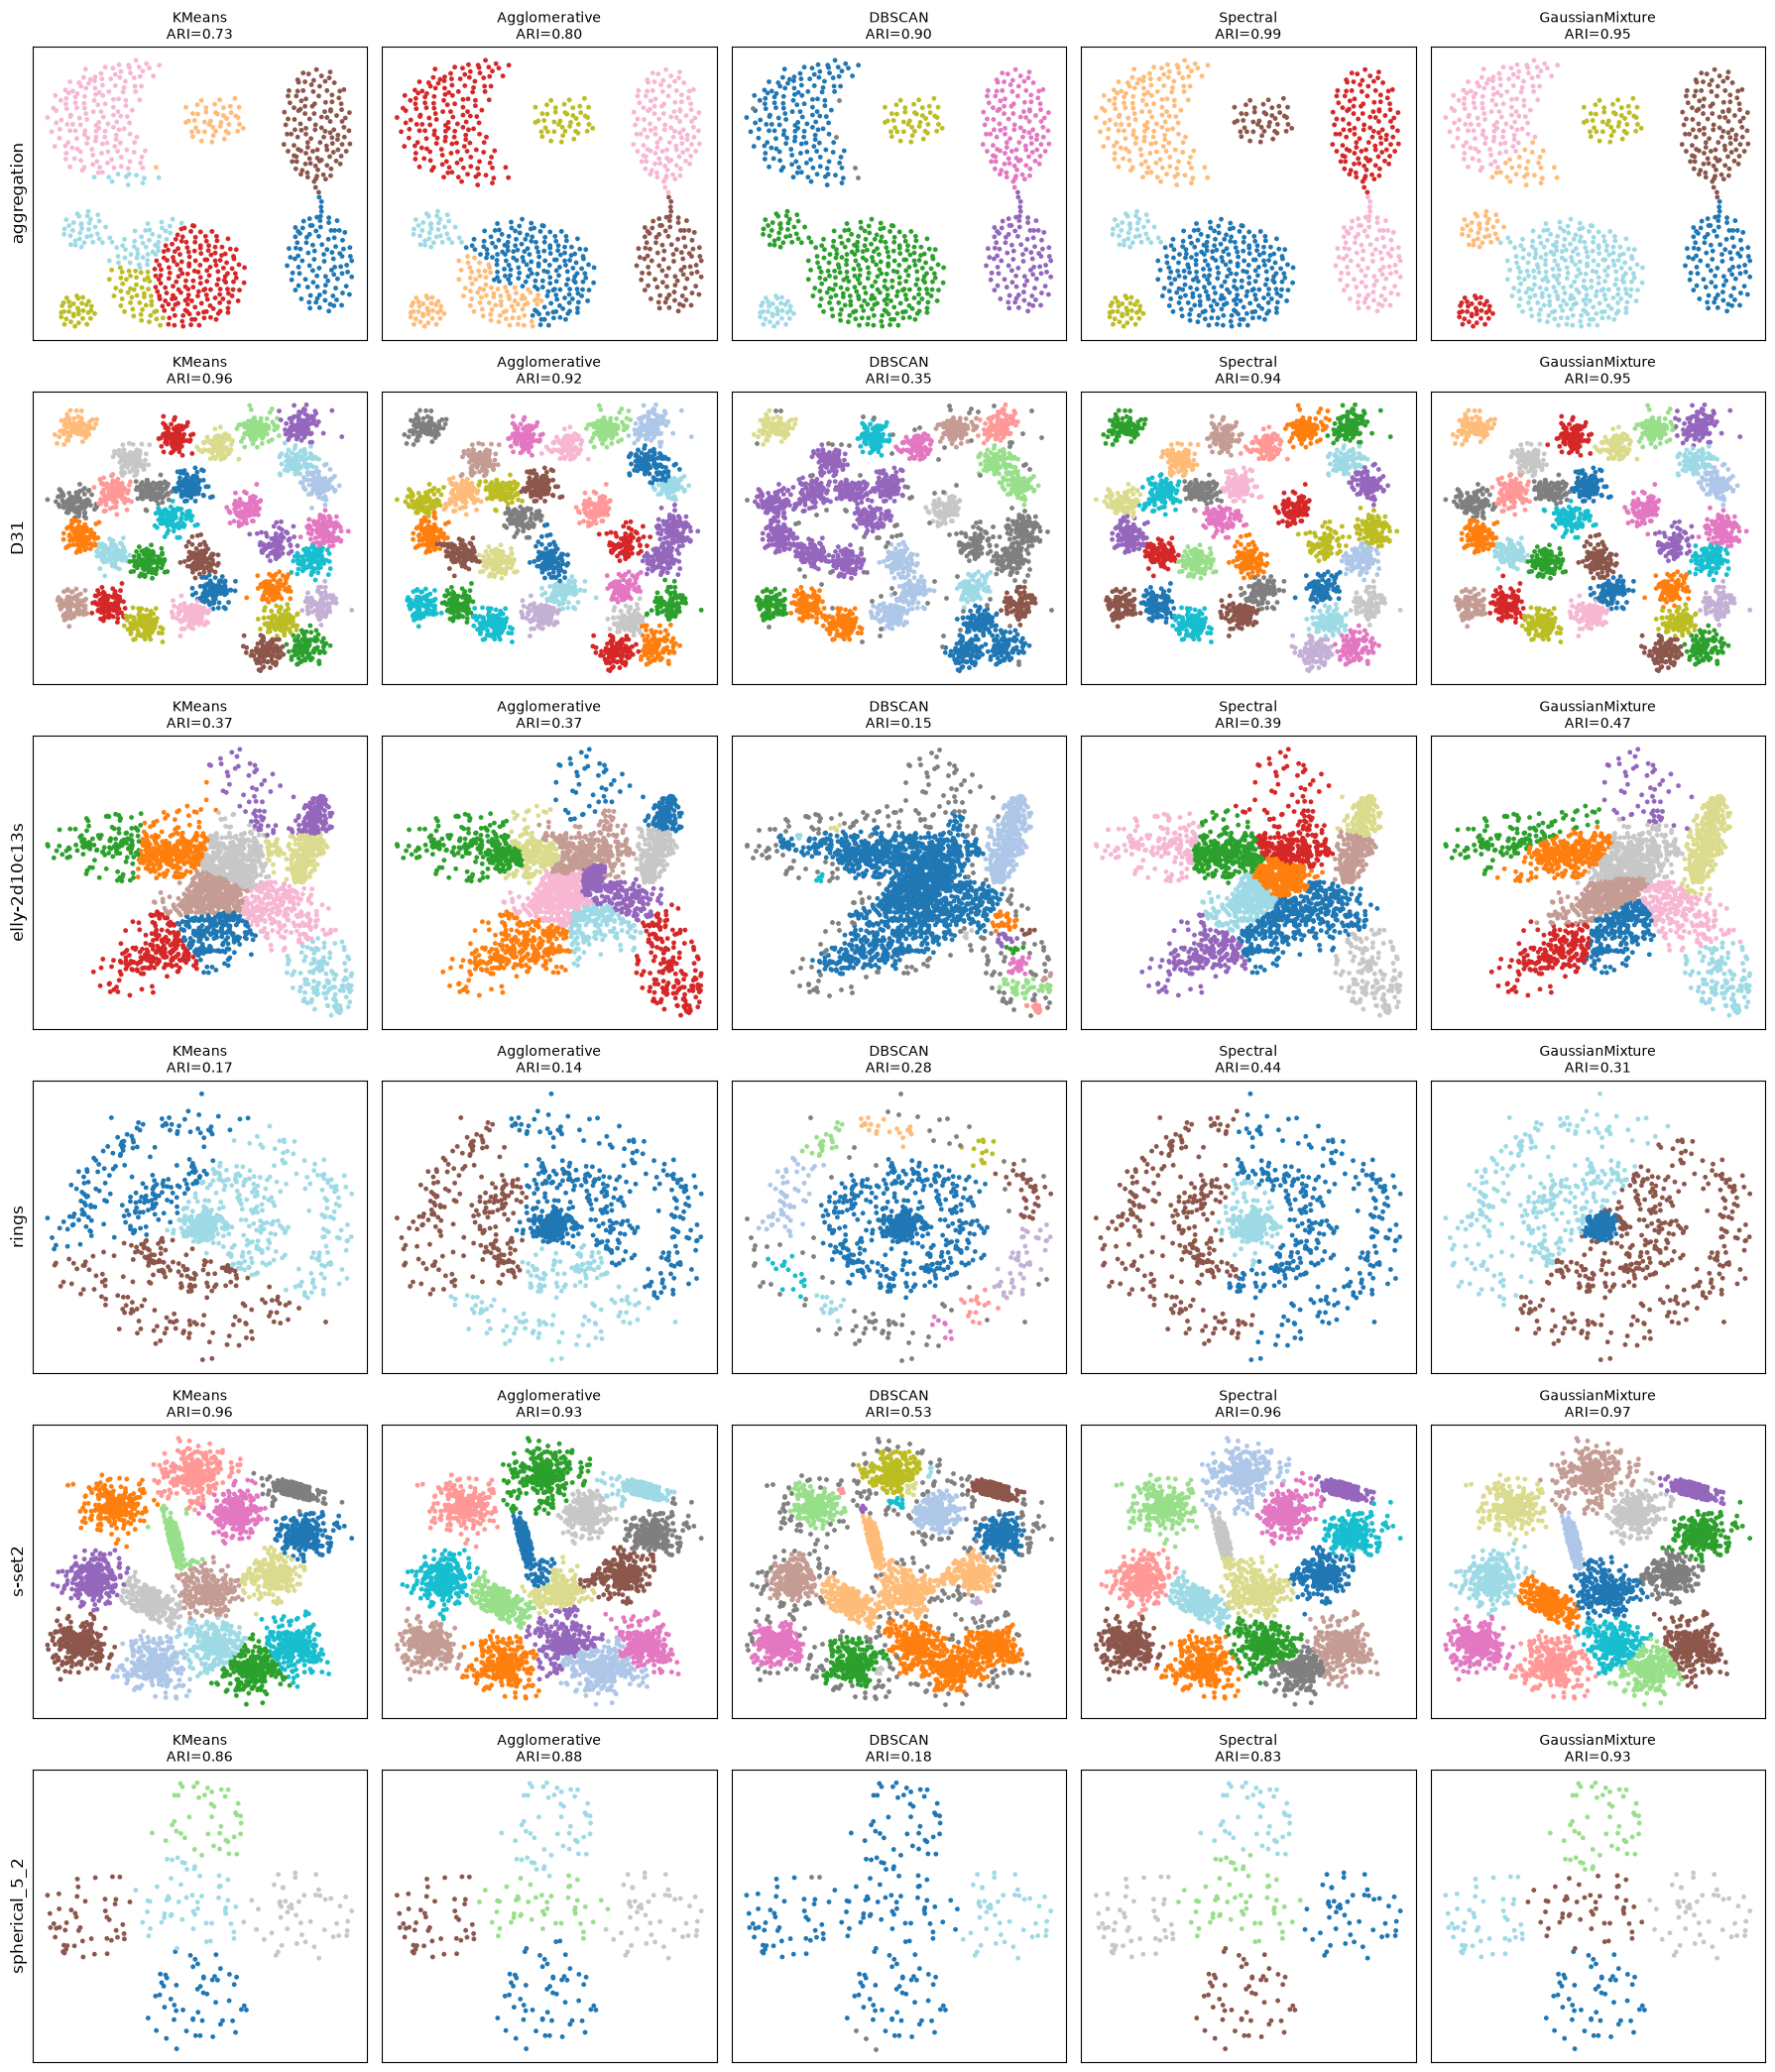

In [8]:
algs = ["KMeans", "Agglomerative", "DBSCAN", "Spectral", "GaussianMixture"]
fig, axs = plt.subplots(len(archivos), len(algs), figsize=(18, 21))
for i, nombre in enumerate(archivos):
    Xn = datos_norm[nombre]
    for j, alg in enumerate(algs):
        lab = predicciones[(nombre, alg)]
        ax = axs[i, j]
        ruido = lab == -1
        ax.scatter(Xn[~ruido, 0], Xn[~ruido, 1], c=lab[~ruido], cmap="tab20", s=6)
        if ruido.any():
            ax.scatter(Xn[ruido, 0], Xn[ruido, 1], c="gray", s=6)
        r = resultados[(resultados.Dataset == nombre) & (resultados.Algoritmo == alg)].iloc[0]
        ax.set_title(f"{alg}\nARI={r.ARI:.2f}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(nombre, fontsize=12)
plt.tight_layout()
plt.savefig("cuadricula_clustering.png", dpi=110)
plt.show()

## 8. Análisis

Algoritmo,KMeans,Agglomerative,DBSCAN,Spectral,GaussianMixture
Dataset,,,,,
D31,0.956,0.917,0.351,0.943,0.946
aggregation,0.727,0.802,0.902,0.990,0.948
elly-2d10c13s,0.373,0.372,0.153,0.387,0.470
rings,0.168,0.142,0.283,0.436,0.306
s-set2,0.958,0.930,0.526,0.957,0.968
spherical_5_2,0.861,0.879,0.182,0.832,0.933


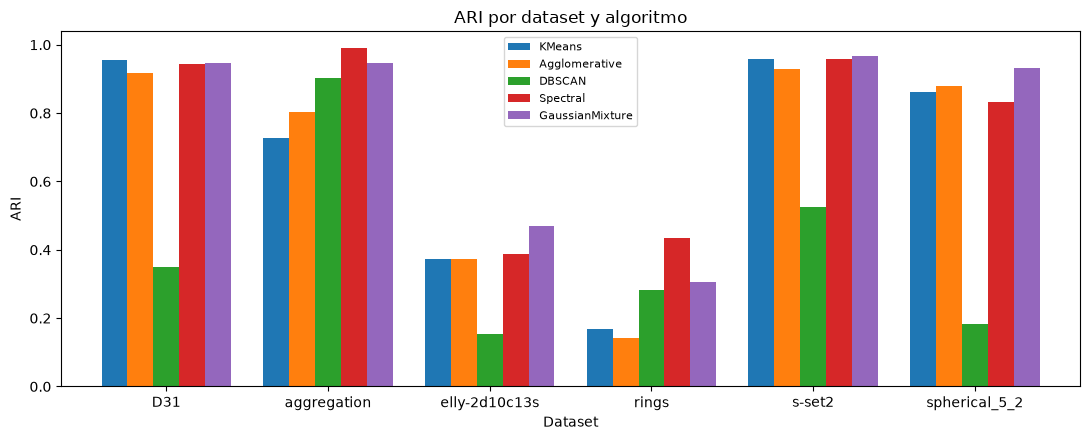

In [9]:
resumen_ari = resultados.pivot(index="Dataset", columns="Algoritmo", values="ARI")[algs]
display(resumen_ari)
resumen_ari.plot(kind="bar", figsize=(11, 4.5), width=0.8)
plt.ylabel("ARI"); plt.title("ARI por dataset y algoritmo"); plt.xticks(rotation=0)
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("ari_barras.png", dpi=110); plt.show()

In [10]:
resultados.to_csv("resultados_clustering.csv", index=False)